# Robust Angular Diameters in Python (`RADPy`) : SED Fitting Tutorial (Single Star)

## Introduction to SED fitting

SED stands for Spectral Energy Distribution. For this purpose, SED fitting describes the process of taking photometry of a star and fitting a model stellar spectrum to that photometry. We use SED fits to determine stellar parameters such as temperature, surface gravity, metallicity, radii, and extinction. 

For interferometric analysis, you need a bolometric flux or $F_{Bol}$ in order to determine the limb darkened angular diameter. To get a bolometric flux, we use SED fits and then integrate under the curve, or model spectrum, over all wavelengths. `RADPy` is outfitted with its own SED fitting module. 

`RADPy` used the Python package `SEDFit` developed by Marina Kounkel (found [here:](https://github.com/mkounkel/SEDFit)), with some adjustments made to the package which are incorporated into the SED fitting module. This package allows you to pick between four different stellar atmospheric models. A breakdown of the coverages between the four models can be seen in the table below:

| Model   | Teff range           | logg range          | Metallicity range      |
|---------|----------------------|---------------------|------------------------|
| Phoenix | $2300 \leq \rm T \leq 12000$ K | $0.0 \leq  \rm logg \leq +6.0$   | $-4.0 \leq \rm [Fe/H] \leq +1.0$|
| Kurucz  | $3750 \leq \rm T \leq 6000$ K  | $0.75 \leq  \rm logg \leq +5.25$ | $-3.0 \leq \rm [M/H] \leq +0.5$ |
| Coelho  | $3000 \leq \rm T \leq 25000$ K | $-0.5 \leq  \rm logg \leq +5.5$  | $0.0017 \leq \rm Z \leq 0.049$  |
| BT-SETTL| $400 \leq \rm T \leq 100000$ K | $-0.5 \leq  \rm logg \leq +5.5 $ | $-1.5 \leq \rm [M/H] \leq +0.5$ |

`SEDFit` contains all the model templates so no downloads are needed. This package performs a multi-component SED fitting routine. It enables a user to fit for some variety of the following parameters:

- Effective temperature, $\rm T_{eff}$
- Surface gravity, $\log{\rm g}$
- Metallicity, $\rm [Fe/H] $
- Distance, $\rm D$
- Extinction, $\rm A_{V}$
- Radius, $\rm R_{\star}$

Currently, `RADPy` allows users to fit for everything except for distance, as `RADPy` extracts a distance from a Gaia parallax or Hipparcos parallax. 

`RADPy` also has a photometry extraction function, which allows a user to pull photometry in common filters from Vizier catalogs. To extract photometry, `RADPy` makes use of the Python package, `astroARIADNE`, developed by Jose Vines (found [here:](https://github.com/jvines/astroARIADNE)). This package has a very useful built-in photometry extraction function and `RADPy` only uses this package for this feature. 

`RADPy` also allows users to use their own input photometry file. Instructions on formatting are found down below in the rest of the tutorial notebook. 

## Installation instructions for `RADPY`'s SED fitting module

Both `SEDFit` and `astroARIADNE` contain dependencies that are unfortunately only compatible with Linux or MacOS systems. If you have either of these, skip the next sections and go down to the section titled "Setting up `SEDFit` and `astroARIADNE`. 

For anyone running Windows, I recommend setting up a WSL virtual environment that runs a Linux distribution. 

I have some general instructions below but please follow the WSL instructions on how to do so. 

### Setting up a virtual environment for Windows

I highly recommend getting Windows Subsystem for Linux (WSL). I use WSL with Ubuntu 24.04. If you do not have WSL, follow their download and set up instructions found [here:](https://ubuntu.com/desktop/wsl). 

I used miniforge in order to install python and conda within WSL. This link [here](https://kirenz.github.io/codelabs/codelabs/miniforge-setup/#0) has some helpful instructions on how to install miniforge if you are interested. Ensure you have a distribution of python that is at least verison 3.12. 

Once you have this in working order, we need to create a virtual environment.

To create your virtual environment, type 
```python
conda create -n [environment name]
```
It will default to the version of python that you currently have installed. 

To indicate which version, just add `python=[version num]` after `[environment name]`. 

Once you have the environment created, follow the install instructions for `RADPy`. This should ensure that all the packages needed for `RADPy` will be downloaded. 

## Setting up `SEDFit` and `astroARIADNE`

Because of these packages dependencies, these packages are not able to be added as a dependency of `RADPy`. To install, follow the instructions below:

### `SEDFit`

To install this package, use the following command:

```python
pip install git+https://github.com/mkounkel/SEDFit.git
```

After installation of `SEDFit`, there is one more step to set up the package. I have added additional filter profiles that `SEDFit` can use for photometry. However, this means you need to add these filter profiles to your install folder of `SEDFit`. 

The package folders are generally located in `path/to/python/distribution/lib/python#.##/site-packages`. 

For my WSL virtual environment, mine is located in `linux/Ubuntu-24.04/home/<user>/miniforge/envs/<name of env>/lib/python3.12/site-packages`.

The filter profiles that you need to add are:

- GAIA.GAIA3.G
- GAIA.GAIA3.Gbp
- GAIA.GAIA3.Grp
- Hipparcos.Hipparcos.Hp_MvB
- Johnson.H
- Johnson.J
- Johnson.K
- Stromgren.b.dat
- Stromgren.u.dat
- Stromgren.v.dat
- Stromgren.y.dat
- TESS.TESS.Red.dat
- TYCHO.TYCHO.B_MvB
- TYCHO.TYCHO.V_MvB

These are needed if you have/want photometry in these bandpasses. If there is a bandpass that doesn't exist (See Step 1 for list of accepted bandpasses), please submit a request or contact me. 

The filter profiles are located on the Github repository in the directory: `radpy/data`. Download these and copy them into the `SEDFit` install file. 

And now you should be all set up with `SEDFit`.

### `astroARIADNE`

If you are interested in having `RADPy` pull photometry for your star for you, you need to install `astroARIADNE`.

To install this package:

```python
pip install astroariadne
```

If you are using `astroARIADNE` for photometry, the package will require dustmaps to be configured. This is already built in the the module and you will see the output of the configuration upon first run. It only needs to be configured once.

For both packages, some of the dependencies that are required for these packages aren't all up to date and/or aren't working properly. This is perfectly fine. You should be able to use the features of the SED fitter without an issue. 

If you have an issue with `dustmaps` and not being able to access the dataverse, please uninstall dustmaps and then use the following commands to reinstall:
```python
pip install git+https://github.com/gregreen/dustmaps.git
```
This will pull the new commits that fix this issue. Before re-running the notebook, refresh your kernel and then also run the following commands:
```python
import dustmaps.sfd
dustmaps.sfd.fetch()
```
If there is one, please submit an issue to `RADPy`'s Github repo. 

## What is in this notebook?

This tutorial is designed to show the general steps on how a user would implement `RADPy` for your own SED fitting needs for single stars. 

This notebook will go over:

1. how to import all the needed modules, 
2. how to have `RADPy` extract photometry for you if you chose, 
3. how to create a photometry file for `RADPy` for your own input photometry file, 
4. how to read in the photometry, 
5. how to perform the SED fit, 
6. how to calculate the bolometric flux, and 
7. how to generate publication ready plots. 


## Usage

If you do use this package, please cite using the citation file located at <https://github.com/spaceashley/radpy> or use the below citation:


### **`RADPy`**
```
@software{Elliott_RADPy_Robust_Angular_2025,
    author = {Elliott, Ashley},
    doi = {10.5281/zenodo.17488122},
    license = {GPL-3.0-only},
    month = sep,
    title = {{RADPy: Robust Angular Diameters in Python}},
    url = {https://github.com/spaceashley/radpy},
    version = {0.10.0},
    year = {2025}
}
```
In addition, make sure you also cite:
### **`ARIADNE`**
```
@ARTICLE{2022MNRAS.tmp..920V,
       author = {{Vines}, Jose I. and {Jenkins}, James S.},
        title = "{ARIADNE: Measuring accurate and precise stellar parameters through SED fitting}",
      journal = {\mnras},
     keywords = {stars:atmospheres, methods:data analysis, stars:fundamental parameters, Astrophysics - Solar and Stellar Astrophysics, Astrophysics - Earth and Planetary Astrophysics, Astrophysics - Instrumentation and Methods for Astrophysics},
         year = 2022,
        month = apr,
          doi = {10.1093/mnras/stac956},
archivePrefix = {arXiv},
       eprint = {2204.03769},
 primaryClass = {astro-ph.SR},
       adsurl = {https://ui.adsabs.harvard.edu/abs/2022MNRAS.tmp..920V},
      adsnote = {Provided by the SAO/NASA Astrophysics Data System}
}
```
### **`SEDFit`**
```
@software{sedfit,
	author = {{Kounkel}, Marina},
	doi = {10.5281/zenodo.8076500},
	month = jun,
	publisher = {Zenodo},
	title = {SEDFit},
	url = {https://doi.org/10.5281/zenodo.8076500},
	year = 2023}
```
## Contact

- Ashley Elliott, (aelli76@lsu.edu)

## Resources
Link to the github repository: <https://github.com/spaceashley/radpy>

Link to the papers for each model:
- BT-Settl: <https://ui.adsabs.harvard.edu/abs/2011ASPC..448...91A/abstract> 

- Kurucz: <https://ui.adsabs.harvard.edu/abs/1992A%26A...264..557B/abstract>

- Coelho: <https://ui.adsabs.harvard.edu/abs/2014MNRAS.440.1027C/abstract> 

- PHOENIX: <https://ui.adsabs.harvard.edu/abs/2013A%26A...553A...6H/abstract>


# Step 1: Setting up for SED Fitting

When you import `radpy.sedfit` several warning messages will appear. Ignore these. These are a combination of some dependencies from `SEDFit` that are being taken care of and some warnings about a few packages that aren't installed for `astroARIADNE` that aren't needed. 

## The Photometry:

### If you are using your own photometry file:
Now that you have everything installed and ready to go, we need to first ensure the photometry is in the correct format. Your photometry file should follow the template provided on the github page for `RADPy`, located in '/radpy/data' entitled 'template_photometry_datafile.csv'. Please download this template and remove the filters you don't need. 

Currently, `RADPy` accepts photometry from the following:

- 2MASS J, H, Ks
- Cousins U, B, V, R, I
- GAIA G, GBp, GRp
- GALEX FUV, NUV
- Johnson U, B, V, R, I, J, K, H
- Hipparcos Hp
- PAN-STARRS PS1 g,r,i,z,y
- SLOAN SDSS u, g, r, i, z
- Spitzer IRAC 3.6, 4.5, 5.8, 8.0
- Spitzer MIPS 24micron
- Stromgren u, v, b, y
- TESS T
- TYCHO Vt, Bt
- WISE W1, W2, W3, W4
- XMM OT V, B, U, UVW1, UVW2, UVM2

If you would like another bandpass, please contact me and I can see about adding it. All of the filter bandpass information, such as reference wavelength, effective width, and zero point, is taken from the SVO filter service (found here: <https://svo2.cab.inta-csic.es/theory/fps/>). 

Once you have your photometry file, save it as a **.csv**. 

If you would like to use your own photometry file, you need to use the filepath to the file and set it to the variable `filename`.

```python
filename = "<path/to/photometry/file>"
```

In [1]:
filename = 'Users/aelliot5/Documents/GitHub/radpy/tutorials/test_data/photometry/HD158259mags.dat'

You also need to create a `StellarParams()` object for `RADPy` to use later on. This is where our results will be stored to use with other features of `RADPy` later on, like fitting for a limb-darkened angular diameter. See the tutorial called "DiameterFittingTutorial_SingleStar" (found [here](https://github.com/spaceashley/radpy/blob/main/tutorials/DiameterFittingTutorial_SingleStar.ipynb)) for more information on what is in the `StellarParams()` object. 

To create a `StellarParams()` object, use the following commands:

```python3
from radpy.stellar import *
from radpy.sedfit import *
star = StellarParams()
```


In [ ]:
from radpy.stellar import *
from radpy.sedfit import *
star = StellarParams()

### If you want to use `RADPy`'s photometry extraction:

`RADPy` uses the photometry extraction within a Python package called `astroARIADNE` developed by Jose Vines (linked here: <https://github.com/jvines/astroARIADNE>). `RADPy`'s use of this package uses the following catalogs to pull photometry: 
 
- Wise (II/328/allwise)
- Gaia (I/355/gaiadr3)
- 2MASS (II/246/out)
- Tycho2 (I/259/tyc2)
- Mermilliod (II/168/ubvmeans)

The `RADPy` accepted filters from `astroARIADNE` are:

- **Johnson U, V, B** 
- **Tycho B, V**
- **Gaia G, GBp, GRp**
- **Cousins R, I**
- **2MASS J, H, Ks**
- **WISE W1, W2**

To use `RADPy`'s photometry extraction, we first need to import the necessary packages:

```python
from radpy.stellar import *
from radpy.sedfit import *
```

Ignore the warnings that might pop involving `pkg_resources` and 'Warning: the passwords of all user accounts have been inactivated'. These warnings relate to the `SEDFit` package and the creator is in the process of fixing them.


and then set up a `StellarObject()`:

```python
starname = '<star name>'
star = StellarParams()
```

In [2]:
from radpy.stellar import *
from radpy.sedfit import *
starname = 'HD 158259'
star = StellarParams()

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


Holoviews not imported. Some visualizations will not be available.
PyMultiNest not imported.  MultiNest fits will not work.
/Users/aelliot5/miniforge3/envs/radpy_env/lib/python3.12/site-packages/astroARIADNE/fitter.py:48: UserWarning: (py)MultiNest installation (or libmultinest.dylib) not detected.
  warnings.warn(


Next we are going to call two functions: `pull_coords` and `pull_gaia_id`. 

These two function obtain the RA and Dec for your star from Simbad and searches for a Gaia ID for your star. 

These functions then add the RA and Dec in both degree units and sexagesimal units to your StellarObject, and the Gaia ID to your StellarObject. 

If you would like to see the output of these functions, simply set `verbose` to `True`.

In [3]:
ra_deg, dec_deg, ra_hms, dec_hms = pull_coords(starname, star, verbose = True)
gaia_id = pull_gaia_id(starname, star, verbose = True)


Coordinates in decimal degrees for HD 158259:
RA: 261.35023036706, Dec: 52.79068607998

Coordinates in sexagesimal format for HD 158259:
RA: 17:25:24.05529, Dec: 52:47:26.46989
Found Gaia DR3 ID: Gaia DR3 1416050859226670848


Great. Now we have our coordinates and our id. Now we can obtain our photometry. 

To extract the photometry, we can use the function `extract_photometry`. 

This function calls `astroARIADNE` and utilizes the photometry extractor built into the package. The output will be a `astroARIADNE Star` object. 

If you would like to see the output of the tool, which will show you the catalogs it searches and the outcome of those searches, set `verbose` to `True`. 

In [4]:
photometry = extract_photometry(starname, star, verbose = True)

Star has Gaia DR3 ID.

		#####################################
		##             ARIADNE             ##
		#####################################
   spectrAl eneRgy dIstribution bAyesian moDel averagiNg fittEr

			Author : Jose Vines
			Contact : jose . vines at ug . uchile . cl
			Star : HD 158259
INFO: Query finished. [astroquery.utils.tap.core]
INFO: Query finished. [astroquery.utils.tap.core]
INFO: Query finished. [astroquery.utils.tap.core]
		--- Retrieved photometry ---
		       Filter       	Magnitude	Uncertainty
		--------------------	---------	-----------
		    STROMGREN_u     	 8.4010  	  0.0729   
		    STROMGREN_v     	 7.4860  	  0.0636   
		    TYCHO_B_MvB     	 7.2050  	  0.0150   
		    STROMGREN_b     	 6.9040  	  0.0598   
		    GaiaDR2v2_BP    	 6.6228  	  0.0030   
		    TYCHO_V_MvB     	 6.5350  	  0.0100   
		    STROMGREN_y     	 6.5190  	  0.0590   
		    GaiaDR2v2_G     	 6.3204  	  0.0028   
		    GaiaDR2v2_RP    	 5.8441  	  0.0038   
		      2MASS_J       	 5.2

The outcome of the `extract_photometry` function displays a table of all the photometry the tool was able to find. Now if you did not use `verbose = True` in the above step and still want to see the photometry table, use 

`photometry.print_mags()`

In [5]:
photometry.print_mags()

		       Filter       	Magnitude	Uncertainty
		--------------------	---------	-----------
		    STROMGREN_u     	 8.4010  	  0.0729   
		    STROMGREN_v     	 7.4860  	  0.0636   
		    TYCHO_B_MvB     	 7.2050  	  0.0150   
		    STROMGREN_b     	 6.9040  	  0.0598   
		    GaiaDR2v2_BP    	 6.6228  	  0.0030   
		    TYCHO_V_MvB     	 6.5350  	  0.0100   
		    STROMGREN_y     	 6.5190  	  0.0590   
		    GaiaDR2v2_G     	 6.3204  	  0.0028   
		    GaiaDR2v2_RP    	 5.8441  	  0.0038   
		      2MASS_J       	 5.2690  	  0.0290   
		      2MASS_H       	 5.0260  	  0.0260   
		      2MASS_Ks      	 4.9650  	  0.0230   
		    WISE_RSR_W1     	 4.9980  	  0.2040   
		    WISE_RSR_W2     	 4.8280  	  0.0940   



You should inspect the photometry the function pulled to ensure that everything looks good. If you have additional photometry that you would like to add (that falls within what `RADPy` can handle), you can use the function:

`add_photometry()`

To use this function, you need your `astroARIADNE Star` object (called `photometry` in this notebook), the filter you would like to include, the magnitude value, and the error for the magnitude. For the filter keywords, see the table below:

|Filter| keyword    | Filter | keyword |
|------|:----------:|--------|:-------:|
|2 MASS H     | 2massh   |Stromgren u  | su       |
|2 MASS J     | 2massj   |Stromgren v  | sv       |
|2 MASS Ks    | 2massk   |Stromgren v  | sv       |
|Cousins I    | ic       |Stromgren b  | sb       |
|Cousins R    | rc       |Stromgren y  | sy       |
|GALEX NUV    | gnuv     |TESS         | tess     |
|GALEX FUV    | gfuv     |PAN-STARRS g | ps1 g    |
|Gaia G       | g        |PAN-STARRS r | ps1 r    |
|Gaia Gbp     | gbp      |PAN-STARRS i | ps1 i    |
|Gaia Grp     | grp      |PAN-STARRS z | ps1 z    |
|TYCHO Bt     | bt       |PAN-STARRS y | ps1 y    |
|TYCHO Vt     | vt       |SDSS u       | sdss u   |
|Johnson U    | u        |SDSS g       | sdss g   |
|Johnson B    | b        |SDSS r       | sdss r   |
|Johnson V    | v        |SDSS i       | sdss i   |
|SDSS z       | sdss z   |WISE W1      | w1       |
|WISE W2      | w2       |WISE W3      | w3       |
|WISE W4      | w4       |             |          |

Here's an example:

Say I want to add a magnitude for 'Cousins R' filter. I would use the keyword: 'rc' and then use the follwoing command:

In [8]:
add_photometry(photometry, 'rc', 5.781557,0.5)
photometry.print_mags()

		       Filter       	Magnitude	Uncertainty
		--------------------	---------	-----------
		    STROMGREN_u     	 8.4010  	  0.0729   
		    STROMGREN_v     	 7.4860  	  0.0636   
		    TYCHO_B_MvB     	 7.2050  	  0.0150   
		    STROMGREN_b     	 6.9040  	  0.0598   
		    GaiaDR2v2_BP    	 6.6228  	  0.0030   
		    TYCHO_V_MvB     	 6.5350  	  0.0100   
		    STROMGREN_y     	 6.5190  	  0.0590   
		    GaiaDR2v2_G     	 6.3204  	  0.0028   
		  GROUND_COUSINS_R  	 5.7816  	  0.5000   
		    GaiaDR2v2_RP    	 5.8441  	  0.0038   
		      2MASS_J       	 5.2690  	  0.0290   
		      2MASS_H       	 5.0260  	  0.0260   
		      2MASS_Ks      	 4.9650  	  0.0230   
		    WISE_RSR_W2     	 4.8280  	  0.0940   



You can now see that I've successfully added the Cousins R magnitude I have.

If you want to remove a magnitude for whatever reason, you are able to do so as well. You would use the function:

`remove_photometry()`

This function requires your `astroARIADNE Star` object and the filter keyword for the magnitude you want to remove. The keywords remain the same as the `addphotometry()` function.

Lets remove the W1 filter.

In [9]:
remove_photometry(photometry, 'w1')
photometry.print_mags()

		       Filter       	Magnitude	Uncertainty
		--------------------	---------	-----------
		    STROMGREN_u     	 8.4010  	  0.0729   
		    STROMGREN_v     	 7.4860  	  0.0636   
		    TYCHO_B_MvB     	 7.2050  	  0.0150   
		    STROMGREN_b     	 6.9040  	  0.0598   
		    GaiaDR2v2_BP    	 6.6228  	  0.0030   
		    TYCHO_V_MvB     	 6.5350  	  0.0100   
		    STROMGREN_y     	 6.5190  	  0.0590   
		    GaiaDR2v2_G     	 6.3204  	  0.0028   
		  GROUND_COUSINS_R  	 5.7816  	  0.5000   
		    GaiaDR2v2_RP    	 5.8441  	  0.0038   
		      2MASS_J       	 5.2690  	  0.0290   
		      2MASS_H       	 5.0260  	  0.0260   
		      2MASS_Ks      	 4.9650  	  0.0230   
		    WISE_RSR_W2     	 4.8280  	  0.0940   



As you can see, the W1 magnitude has been successfully removed!

Once you have your photometry completed, you now need to save the file. To do so, you can use the function:

`save_photometry()`

This function requires you to set an output directory, or where you want your photometry file to be saved. If the directory doesn't exist, the function will create it for you. You also can have the function print out the location of the file that you just saved as well. 

The output of this function will be the filepath to your photometry file to be used in the next step. This function will also save your photometry file with the object name attached to it. 

In [10]:
out_dir = 'test_data/photometry'
filename = save_photometry('HD158259_test', photometry, out_dir, verbose = True)

Directory 'test_data/photometry' created successfully or already exists.
File saved: test_data/photometry/HD158259_testmags.dat


Now my file has been successfully saved. 

This function will save the file and also save the filepath to the variable `filename`. 

The filename (or variable `filename`) is used in Step 2. 

# Step 2: Reading in your photometry

Once you have your photometry file (either your own or using `RADPy`'s photometry extraction), the data need to be read in and organized into the correct format to be used with `RADPy`'s SED fitting module. 

To read in your photometry, you will use the function:

`read_in_photometry()`.

This function does a lot behind the scenes. It does the following:

1. reads in your data file as a `pandas DataFrame`
2. reads in the filter name, and pulls the corresponding filter information from the 'svo_filter_info' file, which contains the reference wavelength ($\rm \mathring{A}$), effective width ($\rm \mathring{A}$), and the zero-point value (mag)
3. converts the magnitudes into fluxes and zero point corrects them
4. determines the error on the zero-point corrected flux value ($\rm \frac{erg}{s~cm^{2}~\mathring{A}}$)
5. reorganizes the data into the correct format for `SEDFit`, which requires the wavelengths to be in units of $\rm \mathring{A}$, the flux to be in $\rm log_{10}(\frac{F}{\lambda})$ and in units of $ \rm \frac{erg}{s~cm^{2}~\mathring{A}}$. 

The final output of this function is an `astropy.Table` that follows the format:
|Index    | sed_filter  |  la     | width    | flux                 | eflux              |
|---------|-------------|---------|----------|----------------------|--------------------|
|         |             |Angstrom | Angstrom | erg/(Angstrom s cm2) |erg/(Angstrom s cm2)|



In [11]:
#If using your own photometry file, give that file path

#If using the photometry file RADPy generated above just use the variable you used in the save_photometry function above. 
phot_data = read_in_photometry(filename)

Let's check and see if the data were read in properly.

In [12]:
phot_data

index,sed_filter,la,width,flux,eflux
,,Angstrom,Angstrom,erg / (Angstrom s cm2),erg / (Angstrom s cm2)
int64,str17,float64,float64,float64,float64
0,Stromgren.u,3443.6,186.22,-8.312293067898654,0.03633239405994358
1,Stromgren.v,4105.46,111.99,-7.519443432957726,0.033424634820775255
2,TYCHO.TYCHO.B_MvB,4194.96,370.695,-7.438266603920657,0.022513133845333516
3,Stromgren.b,4666.25,101.04,-7.330206282819503,0.03228437277909189
4,GAIA.GAIA3.Gbp,5109.71,1078.75,-7.330221151098504,0.02173310948349352
5,TYCHO.TYCHO.V_MvB,5300.19,566.775,-7.2941748642333835,0.022065092547459583
6,Stromgren.y,5474.17,126.65,-7.310537159431749,0.03204832196456094
7,GAIA.GAIA3.G,6217.59,2026.485,-7.335927877353823,0.021728844871176007


Okay now that our photometry file has been read in and reformatted, lets move to the next step.

# Step 3: Setting up your star

Aside from the photometry data, we need a `StellarParams()` object, which will allow us to store our results to use with other features of `RADPy` later on, like fitting for a limb-darkened angular diameter. See the tutorial called SingleStarTutorial, for more details on what is in the `StellarParams()` object. 

You should have already made the `StellarObject()` in either of the above steps. Now lets add the needed information to do an SED fit with `RADPy`. 

To perform an SED fit with `RADPy`, you need the following input information about your star:

- $\log{\rm g}$ and its error in cgs units
- [Fe/H] and it error

You will also need the RA and Dec coordinates if you haven't done so already for your star.

In [13]:
starname = 'HD 158259'
logg = 4.21
dlogg = 0.33
m = 0.0
dm = 0.12
star.logg = logg
star.logg_err = dlogg
star.feh = m
star.feh_err = dm
ra_deg, dec_deg, ra_hms, dec_hms = pull_coords(starname, star, verbose = True)


Coordinates in decimal degrees for HD 158259:
RA: 261.35023036706, Dec: 52.79068607998

Coordinates in sexagesimal format for HD 158259:
RA: 17:25:24.05529, Dec: 52:47:26.46989


Let's double check and make sure it worked.

In [14]:
star

fbol = None [10⁻⁸ erg/s/cm²]
fbol_err = None [10⁻⁸ erg/s/cm²]
logg = 4.21 [dex]
logg_err = 0.33 [dex]
feh = 0.0 [dex]
feh_err = 0.12 [dex]
plx = None [mas]
plx_err = None [mas]
dist = None [pc]
dist_err = None [pc]
udthetai = None [mas]
udthetai_err = None [mas]
ldthetai = None [mas]
ldthetai_err = None [mas]
udtheta = None [mas]
udtheta_err = None [mas]
ldtheta = None [mas]
ldtheta_err = None [mas]
teff = None [K]
teff_err = None [K]
lum = None [L☉]
lum_err = None [L☉]
rad = None [R☉]
rad_err = None [R☉]
ldc_R = None [ ]
ldc_K = None [ ]
ldc_H = None [ ]
ldc_J = None [ ]
ra_deg = 261.35023036706
dec_deg = 52.79068607998
ra_hms = 17:25:24.05529
dec_dms = 52:47:26.46989
GaiaDR3ID = 1416050859226670848

Good. We now have populated the `StellarParams()` object with some input information.

Next step is we need to get a distance. If you already have a zero-point corrected distance, you can just add it to the `StellarParams()` object using the following:

`star.dist = D`

`star.dist_err = dD`

But if you don't have a distance yet, don't worry, `RADPy` grabs it for you. To do so, use the following:

In [15]:
D, dD = distances('HD 158259', verbose = True)
star.dist = D
star.dist_err = dD

Found Gaia DR3 ID: Gaia DR3 1416050859226670848
Corrected parallax: 36.99638 [mas]
Distance: 27.02967 +/- 0.01451 [pc]


Great. Now we have all the stellar parameters we need to start our fitting. 

# Step 4: Perform the SED fit

To perform an SED fit, `RADPy` uses `SEDFit` as described in the introduction. This package requires a few input statements from the user. You need to know which model you would like to use, what parameters you want to fit for, and the ranges of those fit parameters. 

For models, you can chose between 4 different options:

|Model     | keyword    |
|----------|------------|
|BT-SETTL  | `'btsettl'`|
|PHOENIX   | `'phoenix'`|
|Coelho    | `'coelho'` |
|Kurucz    | `'kurucz'` |

You can fit for the following parameters:

- Temperature (Teff)
- Surface gravity (logg)
- [Fe/H]
- Radius
- Extinction ($\rm A_{V} $)

It is allowed to not fit for these values, i.e. set $\rm A_{V} = 0$. If you do chose to fit for any of these parameters, you must add a range of values in which you want to have the fit search through. For example, if you are fitting for temperature, you need a range of temperature values to give the model, such as `teffrange = [5000, 7000]`. 

The inputs into the function are as follows:

|Parameter         | What is it?                                                      | Example syntax            |
|------------------|------------------------------------------------------------------|---------------------------|
|  `x`             | `astropy.Table` containing your photometry                       | `phot_data`               |
|  `star`          | `StellarParams()` object                                         |  `star`                   |
|  `initial_guess` | Array of your initial guesses for the fit.                       | `[5000, 4.5, 0.2, 0]`     |
|                  |   Even if you are fixing a parameter, set the                    |                           | 
|                  |  initial guess in the format: [Teff, logg, [Fe/H], $\rm A_{V} $] |                           |
|`num_iter`        | Number of iterations for the Monte Carlo   | `num_iter = 10` |
|                  | simulation for the bolometric flux         |    |
| `unit`           | What unit your bolometric flux will be in  | `unit = 'AA'` |
|                  |Options are angstrom ('AA') or micron ('micron') | |
| `model`          | Set the keyword for which model you want to use                  |  `model = 'phoenix'`      |
|  `teffrange`     | If fitting for Teff, set your range of values.                   |  `teffrange = [5000,8000]`|
|                  |  Format: [min value, max value]                                  |                           |
|  `loggrange`     | If fitting for logg, set your range of values.                   |  `loggrange = [2.5,5.0]`  |
|                  |  Format: [min value, max value]                                  |                           |
|  `fehrange`      | If fitting for [Fe/H], set your range of values.                 |  `fehrange = [-1.0, 1.0]` |
|                  |  Format: [min value, max value]                                  |                           |
|  `avrange`       | If fitting for $\rm A_{V}$, set your range of values.            |  `avrange = [0, 1]`       |
|                  |  Format: [min value, max value]                                  |                           |
|  `fitT`          | If fitting for Teff, set equal to `True`.                        |   `fitT = True`           |
|                  | Default is `False`                                               |                           |
|  `fit_logg`      | If fitting for logg, set equal to `True`.                        |   `fit_logg = True`       |
|                  | Default is `False`                                               |                           |
|  `fit_feh`       | If fitting for [Fe/H], set equal to `True`.                      |   `fit_feh = True`        |
|                  | Default is `False`                                               |                           |
|  `fit_av`        | If fitting for $\rm A_{V}$, set equal to `True`.                 |   `fit_av = True`         |
|                  | Default is `False`                                               |                           |
| `verbose`        | If True, returns print statements.                               |    `verbose = True`       |
|                  | Useful for debugging. Default is set to `False`                  |                           |

This function also calculates the bolometrix flux and the error on the bolometric flux of your star given the photometry file. To do this, it take the photometry, samples on a normal distribution, and then fits the randomly sampled photometry. With the resulting fit, `RADPy` then integrates under the model curve and then stores this value in an array (aka the bolometric flux). `RADPy` runs a Monte Carlo simulation for the number of iterations indicated by the user with the `num_iter` variable. The final product is an array of bolometric fluxes. The final bolometric flux is the average of the array and the final error is the standard deviation and a 2% error added in quadrature. 

If `verbose` is set to `True`, the function will output the process of the function as it goes through and then will display the following:
- the bolometric flux and error
- the Fbol precision
- the star's distance
- the extinction parameter
- the radius
- temperature
- $\log{\rm g}$
- [Fe/H]

This function will also store the $\chi^{2}$, $\chi^{2}_{red}$ and the fitted values from the SED. `RADPy` also stores the SED fitted parameters automatically into the `StellarParams()` object just for comparison purposes later on. 

Alright, lets run a fit. 

(Warnings might appear about cuda drivers. Ignore these. The fit works without them.)


In [16]:
initial_guess = [5850, 4.21, 0.0, 0.0]
unit = 'AA'
model = 'phoenix'
num_iter = 10
sed_fit = fit_sed(phot_data, star, initial_guess, num_iter, unit, model, teffrange = [5000,7000], fitT = True, verbose = True)

Initializing SEDFit object...
Setting up a generic star
Gaia parallax is not available, distance is arbitrarily set by default and should be manually adjusted.
Maximum Av along the line of sight is 10
Starting 10 iterations...
Bolometric flux:  6.7079 +/- 0.16107 x 10^{-8) erg/s/cm^2
Fbol precision:  2.401 %
Distance: 27.02967 pc
AV: 0.0 mag
Radius: 1.3426231691424724 Rsun
Teff: 5558.86842845397 K
Log g: 4.21 
Fe/H: 0.0


And now we have a bolometric flux!!

## Step 5: Plotting the SED fit

`RADPy` will also plot your SED on a publication ready graphic. The plotting function is called `plot_sed`. It has a few inputs to be aware of.

|Input            |   What is it?                                        | Example syntax                    |
|-----------------|------------------------------------------------------|-----------------------------------|
|  `sed_fit`      |  Your fit object created after running `fit_sed`     | `sed_fit`                         |
|  `unit`         | What wavelength unit you want your plot in           |   `'AA'`                          |
|                 | Options are Angstroms (`'AA'`) or microns `'micron'` |                                   |
| `logplot`       | Set True if you want your plot in log space          |   `logplot = True`                |
|                 | Default is True                                      |                                   |
| `fbol_lam`      | Set True if you want your flux to be multiplied      | `fbol_lam = True`                 |
|                 | by the wavelength, Default is True.                  |                                   |
| `set_axis`      | Set the axis range of your plot                      | `set_axis = [3.5, 4.5, -8.5, -7]` |
|                 | Needs to be in the correct space for the plot        |                                   |
|                 | If nothing is set, `RADPy` will set it for you       |                                   |
|                 | based on the model ranges                            |                                   |
| `title`         | Allows user to add a title to the plot.              | `title = 'HD # SED fit'`          |
| `uselatex`      | Allows user to use latex interpreter for plot labels | `uselatex = True`                 |
|                 | Default is set to False.                             |                                   |
| `savefig`       | Allows user to save the figure.                      | `savefig = 'HD#SEDfit.png`        |
| `show`          | Displays the figure to you. Default is True.         | `show = True`                     |

Let's plot.

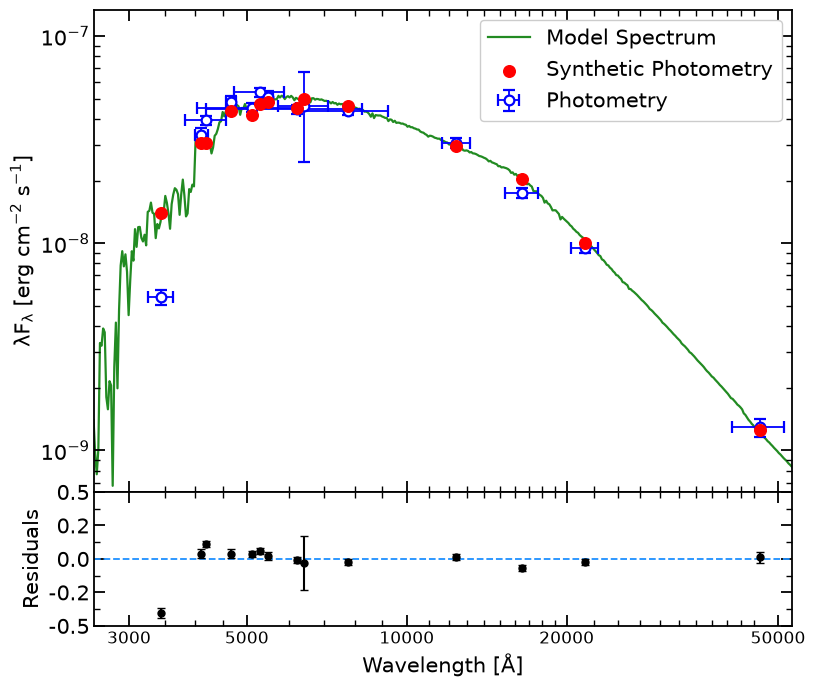

(<Figure size 900x800 with 2 Axes>,
 array([<Axes: ylabel='$\\rm \\lambda F_{\\lambda}~[\\mathrm{erg~cm^{-2}~s^{-1}}]$'>,
        <Axes: xlabel='$ \\rm Wavelength~[\\AA]$', ylabel='Residuals'>],
       dtype=object))

In [17]:
#set_axis = [3.5,4.5, -8.5,-7]
plot_sed(sed_fit, 'AA', logplot = True, fbol_lam = True, title = None, savefig = None, show = True)

Below is what the plot looks like with the `uselatex` flag set to `True`.

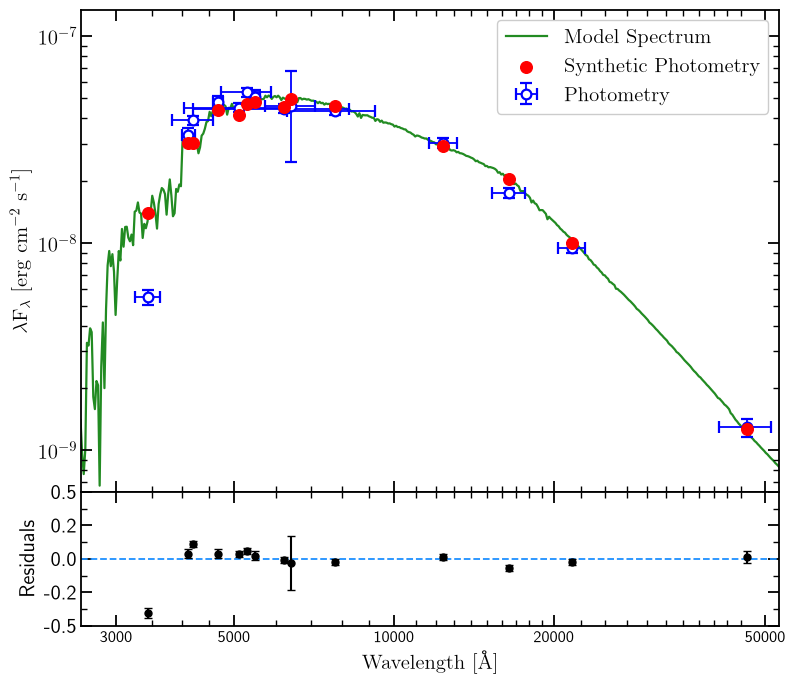

(<Figure size 900x800 with 2 Axes>,
 array([<Axes: ylabel='$\\rm \\lambda F_{\\lambda}~[\\mathrm{erg~cm^{-2}~s^{-1}}]$'>,
        <Axes: xlabel='$ \\rm Wavelength~[\\AA]$', ylabel='Residuals'>],
       dtype=object))

In [18]:
#set_axis = [3.5,4.5, -8.5,-7]
plot_sed(sed_fit, 'AA', logplot = True, fbol_lam = True, title = None, uselatex = True, savefig = None, show = True)